In [66]:
from pathlib import Path
import base64
import textwrap

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image, ImageOps, ImageDraw, ImageFont

REPO_ROOT = Path('/Users/ricardorivero/Documents/GitHub/HantaReassortment')
FIG_DIR = REPO_ROOT / 'notebooks' / 'figures'
TMP_DIR = FIG_DIR / '_tmp_fig4_panels'
TMP_DIR.mkdir(exist_ok=True)

HIER_DIR = REPO_ROOT / 'model_test' / 'runs' / 'model_site' / 'hierarchical_block_comparison_direct516_plus_pathoplexus_andes_full'
SHAP_FIG = FIG_DIR / 'figure3_integrated_explanation_architecture_vb_biology_only.png'
CLUSTER_TABLE = REPO_ROOT / 'final_model' / 'repeated_stratified' / 'runs' / 'direct516_biology_with_utr_lgbm_untuned_ld_interaction_only_no_utr_coverage' / 'integrated_top_feature_clusters.tsv'

OUT_PNG = FIG_DIR / 'figure4_one_top_three_bottom_wide_prunedC.png'
OUT_SVG = FIG_DIR / 'figure4_one_top_three_bottom_wide_prunedC.svg'
OUT_PDF = FIG_DIR / 'figure4_one_top_three_bottom_wide_prunedC.pdf'

mpl.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': ['Helvetica Neue', 'Helvetica', 'Arial', 'DejaVu Sans'],
    'font.size': 7,
    'axes.labelsize': 8,
    'xtick.labelsize': 7,
    'ytick.labelsize': 7,
    'legend.fontsize': 6,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.facecolor': 'white',
    'figure.facecolor': 'white',
    'savefig.facecolor': 'white',
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
})

In [67]:
def open_white(path):
    im = Image.open(path).convert('RGBA')
    bg = Image.new('RGBA', im.size, 'white')
    bg.alpha_composite(im)
    return bg.convert('RGB')


def trim_white(im, pad=18, thresh=249):
    arr = np.asarray(im.convert('L'))
    mask = arr < thresh
    if not mask.any():
        return im
    ys, xs = np.where(mask)
    return im.crop((
        max(int(xs.min()) - pad, 0),
        max(int(ys.min()) - pad, 0),
        min(int(xs.max()) + pad, im.width),
        min(int(ys.max()) + pad, im.height),
    ))


def wrap_label(s, width=16, max_lines=3):
    s = str(s)
    replacements = {
        'ld site': 'LD site',
        'UTR5 M structural distance SD': 'UTR5 M structural\ndistance SD',
    }
    for old, new in replacements.items():
        s = s.replace(old, new)
    if '\n' in s:
        return s
    return '\n'.join(textwrap.wrap(s, width=width, break_long_words=False)[:max_lines])


def helvetica_font(size):
    for fp in ['/System/Library/Fonts/HelveticaNeue.ttc', '/System/Library/Fonts/Supplemental/Helvetica.ttf']:
        try:
            return ImageFont.truetype(fp, size)
        except Exception:
            pass
    return ImageFont.load_default()


def write_png_wrapped_svg(png_path, svg_path, width_px, height_px):
    data = base64.b64encode(Path(png_path).read_bytes()).decode('ascii')
    svg = f'''<svg xmlns="http://www.w3.org/2000/svg" width="{width_px}" height="{height_px}" viewBox="0 0 {width_px} {height_px}">
  <image href="data:image/png;base64,{data}" width="{width_px}" height="{height_px}"/>
</svg>
'''
    Path(svg_path).write_text(svg)


In [68]:
family_colors = {
    'Host life history': '#4daf8b',
    'Host phylogenetic diversity': '#88c999',
    'Overlap opportunity': '#e3b34c',
    'Local host prevalence': '#d9a441',
    'LD / coadaptation': '#d95f5f',
    'UTR structure': '#9b6fb6',
    'Tree incongruence': '#708090',
    'Geographic / sampling context': '#7fa4b7',
    'Controls / sampling': '#b7b7b7',
    'Species identity': '#6c8ebf',
}


def make_panel_b(cluster_path=CLUSTER_TABLE, outpath=TMP_DIR / 'panel_B_clusters_uncropped.png'):
    cluster = pd.read_csv(cluster_path, sep='	')
    plot_clusters = cluster[cluster['family_Controls / sampling'] < cluster['combined_effect']].copy()
    plot_clusters = plot_clusters.sort_values('combined_effect', ascending=False).head(9)
    plot_clusters = plot_clusters.sort_values('combined_effect', ascending=True).reset_index(drop=True)

    fig, ax = plt.subplots(figsize=(4.4, 4.35), dpi=300)
    y = np.arange(len(plot_clusters))
    left = np.zeros(len(plot_clusters))

    for fam, color in family_colors.items():
        col = f'family_{fam}'
        if col not in plot_clusters.columns:
            continue
        vals = plot_clusters[col].to_numpy(float)
        if np.allclose(vals, 0):
            continue
        ax.barh(y, vals, left=left, color=color, edgecolor='none', height=0.72)
        left += vals

    ax.set_yticks(y)
    ax.set_yticklabels(plot_clusters['rank'].astype(str))
    ax.set_xlabel('Combined mean absolute contribution')
    ax.set_ylabel('Feature cluster')
    xmax = float(plot_clusters['combined_effect'].max()) * 1.42
    ax.set_xlim(0, xmax)

    for yi, (_, row) in zip(y, plot_clusters.iterrows()):
        ax.text(row['combined_effect'] + xmax * 0.025, yi, wrap_label(row['exemplar_label']), va='center', fontsize=6.7)

    ax.tick_params(axis='y', pad=3)
    ax.grid(False)
    fig.tight_layout(pad=0.6)
    fig.savefig(outpath, dpi=300)
    plt.close(fig)
    return outpath

panel_b_path = make_panel_b()
panel_b_path

PosixPath('/Users/ricardorivero/Documents/GitHub/HantaReassortment/notebooks/figures/_tmp_fig4_panels/panel_B_clusters_uncropped.png')

In [69]:
coef_colors = {
    'Host ecology': '#2A9D8F',
    'Host traits': '#2A9D8F',
    'Molecular': '#4F6F8F',
    'Interaction': '#C44E52',
}

term_labels = {
    'hosttrait_combine_adult_mass_g_z': 'Adult mass',
    'hosttrait_combine_litter_size_n_z': 'Litter size',
    'hosttrait_combine_gestation_length_d_z': 'Gestation length',
    'hosttrait_combine_dispersal_km_z': 'Dispersal',
    'species_feat_hostdiv_faith_pd_z': "Host Faith's PD",
    'overlap_opportunity_local_z': 'Host-overlap opportunity',
    'arha_prev_local_z': 'Local prevalence',
    'species_feat_mean_cramers_v_overall_z': 'Cross-segment coupling',
    'species_feat_prop_significant_overall_z': 'Linked-site fraction',
    'species_feat_utr5_L_structdist_mean_z': 'L UTR5 structure',
    'species_feat_utr3_L_structdist_mean_z': 'L UTR3 structure',
    'overlap_opportunity_local_z:species_feat_mean_cramers_v_overall_z': 'Overlap x coupling',
    'overlap_opportunity_local_z:species_feat_utr5_L_structdist_mean_z': 'Overlap x L-UTR',
}

coef_order = [
    'overlap_opportunity_local_z',
    'arha_prev_local_z',
    'species_feat_hostdiv_faith_pd_z',
    'hosttrait_combine_adult_mass_g_z',
    'hosttrait_combine_litter_size_n_z',
    'hosttrait_combine_gestation_length_d_z',
    'hosttrait_combine_dispersal_km_z',
    'species_feat_mean_cramers_v_overall_z',
    'species_feat_prop_significant_overall_z',
    'species_feat_utr5_L_structdist_mean_z',
    'species_feat_utr3_L_structdist_mean_z',
    'overlap_opportunity_local_z:species_feat_mean_cramers_v_overall_z',
    'overlap_opportunity_local_z:species_feat_utr5_L_structdist_mean_z',
]

coef_groups = {term: 'Host ecology' for term in coef_order}
for term in ['hosttrait_combine_adult_mass_g_z', 'hosttrait_combine_litter_size_n_z', 'hosttrait_combine_gestation_length_d_z', 'hosttrait_combine_dispersal_km_z']:
    coef_groups[term] = 'Host traits'
for term in ['species_feat_mean_cramers_v_overall_z', 'species_feat_prop_significant_overall_z', 'species_feat_utr5_L_structdist_mean_z', 'species_feat_utr3_L_structdist_mean_z']:
    coef_groups[term] = 'Molecular'
for term in coef_order[-2:]:
    coef_groups[term] = 'Interaction'


def build_pruned_coefficient_table(hier_dir=HIER_DIR):
    rows = []
    main = pd.read_csv(hier_dir / 'integrated_plus_utr3_block' / 'posterior_summary.tsv', sep='	').set_index('term')

    for term in coef_order[:-2]:
        r = main.loc[term]
        rows.append({
            'term': term,
            'label': term_labels[term],
            'group': coef_groups[term],
            'mean': r['mean'],
            'lo': r['hdi_3%'],
            'hi': r['hdi_97%'],
        })

    interaction_sources = [
        ('integrated_overlap_ld_interaction', 'overlap_opportunity_local_z:species_feat_mean_cramers_v_overall_z'),
        ('integrated_overlap_utrL_interaction', 'overlap_opportunity_local_z:species_feat_utr5_L_structdist_mean_z'),
    ]
    for subdir, term in interaction_sources:
        df = pd.read_csv(hier_dir / subdir / 'posterior_summary.tsv', sep='	').set_index('term')
        r = df.loc[term]
        rows.append({
            'term': term,
            'label': term_labels[term],
            'group': coef_groups[term],
            'mean': r['mean'],
            'lo': r['hdi_3%'],
            'hi': r['hdi_97%'],
        })

    coef = pd.DataFrame(rows)
    coef['y'] = np.arange(len(coef))[::-1]
    return coef


def make_panel_c(hier_dir=HIER_DIR, outpath=TMP_DIR / 'panel_C_pruned_former_colors.png'):
    coef = build_pruned_coefficient_table(hier_dir)

    fig, ax = plt.subplots(figsize=(4.4, 4.35), dpi=300)
    for _, r in coef.iterrows():
        color = coef_colors[r['group']]
        ax.hlines(r['y'], r['lo'], r['hi'], color=color, lw=2.1, alpha=0.95, zorder=2)
        ax.scatter(r['mean'], r['y'], s=34, color=color, edgecolor='k', linewidth=0.6, zorder=3)

    ax.axvline(0, color='k', lw=1.1, ls=(0, (3, 2)))
    ax.set_yticks(coef['y'])
    ax.set_yticklabels(coef['label'])
    ax.set_xlabel('Posterior coefficient')
    ax.set_xlim(-2.7, 2.2)
    ax.set_ylim(-0.8, len(coef) - 0.2)
    ax.grid(axis='x', color='#e6e6e6', lw=0.8, zorder=0)

    handles = [
        plt.Line2D([0], [0], marker='o', lw=0, color=coef_colors[g], markersize=4, label=g)
        for g in ['Host ecology', 'Molecular', 'Interaction']
    ]
    ax.legend(handles=handles, frameon=False, fontsize=6, loc='lower left', bbox_to_anchor=(0, 1.005), ncol=3, handletextpad=0.3, columnspacing=0.8)

    fig.tight_layout(pad=0.6)
    fig.savefig(outpath, dpi=300)
    plt.close(fig)
    return outpath

panel_c_path = make_panel_c()
panel_c_path

PosixPath('/Users/ricardorivero/Documents/GitHub/HantaReassortment/notebooks/figures/_tmp_fig4_panels/panel_C_pruned_former_colors.png')

In [70]:
species_model_colors = {
    'species_only': '#8E9BB0',
    'integrated_plus_utr3_block': '#C44E52',
}
species_model_labels = {
    'species_only': 'Species only',
    'integrated_plus_utr3_block': 'Integrated + UTR3',
}
species_name_map = {
    'orthohantavirus_andesense': 'ANDV',
    'orthohantavirus_hantanense': 'HTNV',
    'orthohantavirus_tulaense': 'TULV',
    'orthohantavirus_puumalaense': 'PUUV',
    'orthohantavirus_seoulense': 'SEOV',
    'orthohantavirus_sinnombreense': 'SNV',
    'orthohantavirus_dobravaense': 'DOBV',
}
species_order = ['DOBV', 'SNV', 'SEOV', 'PUUV', 'TULV', 'HTNV', 'ANDV']


def make_panel_d(hier_dir=HIER_DIR, outpath=TMP_DIR / 'panel_D_species_effects_wide.png'):
    sp = pd.read_csv(hier_dir / 'species_random_effects.tsv', sep='	')
    sp = sp[sp['model'].isin(species_model_colors)].copy()
    sp['abbr'] = sp['species'].map(species_name_map)
    sp['ybase'] = sp['abbr'].map({s: i for i, s in enumerate(species_order[::-1])})

    fig, ax = plt.subplots(figsize=(4.4, 4.35), dpi=300)
    for model, offset in [('species_only', -0.12), ('integrated_plus_utr3_block', 0.12)]:
        df = sp[sp['model'] == model]
        for _, r in df.iterrows():
            y = r['ybase'] + offset
            ax.hlines(y, r['hdi_3%'], r['hdi_97%'], color=species_model_colors[model], lw=2.1, alpha=0.95)
            ax.scatter(r['mean'], y, s=34, color=species_model_colors[model], edgecolor='k', linewidth=0.6, zorder=3)

    ax.axvline(0, color='k', lw=1.1, ls=(0, (3, 2)))
    ax.set_yticks(range(len(species_order)))
    ax.set_yticklabels(species_order[::-1])
    ax.set_xlabel('Species random effect')
    ax.set_xlim(-7, 4)
    ax.grid(axis='x', color='#e6e6e6', lw=0.8, zorder=0)

    handles = [
        plt.Line2D([0], [0], marker='o', lw=0, color=species_model_colors[m], markersize=4, label=species_model_labels[m])
        for m in ['species_only', 'integrated_plus_utr3_block']
    ]
    ax.legend(handles=handles, frameon=False, fontsize=6, loc='lower right')

    fig.tight_layout(pad=0.6)
    fig.savefig(outpath, dpi=300)
    plt.close(fig)
    return outpath

panel_d_path = make_panel_d()
panel_d_path

PosixPath('/Users/ricardorivero/Documents/GitHub/HantaReassortment/notebooks/figures/_tmp_fig4_panels/panel_D_species_effects_wide.png')

In [71]:
def make_figure4(
    shap_fig=SHAP_FIG,
    panel_b=panel_b_path,
    panel_c=panel_c_path,
    panel_d=panel_d_path,
    out_png=OUT_PNG,
    out_svg=OUT_SVG,
    out_pdf=OUT_PDF,
):
    shap_img = open_white(shap_fig)

    # Panel A is currently taken from the existing SHAP explanation figure.
    # Rebuilding panel A directly from the SHAP tables would remove the embedded old panel letters.
    panel_a = trim_white(shap_img.crop((10, 0, 3838, 1360)), 18)
    panel_b_img = Image.open(panel_b).convert('RGB')
    panel_c_img = Image.open(panel_c).convert('RGB')
    panel_d_img = Image.open(panel_d).convert('RGB')

    canvas_w = 4600
    margin = 145
    gap_y = 130
    gap_x = 110
    full_w = canvas_w - 2 * margin
    top_h = 1580
    bottom_h = 1650
    panel_w = (full_w - 2 * gap_x) // 3
    canvas_h = 2 * margin + gap_y + top_h + bottom_h

    canvas = Image.new('RGB', (canvas_w, canvas_h), 'white')
    slots = [
        (margin, margin, full_w, top_h, panel_a, 'a)'),
        (margin, margin + top_h + gap_y, panel_w, bottom_h, panel_b_img, 'b)'),
        (margin + panel_w + gap_x, margin + top_h + gap_y, panel_w, bottom_h, panel_c_img, 'c)'),
        (margin + 2 * (panel_w + gap_x), margin + top_h + gap_y, panel_w, bottom_h, panel_d_img, 'd)'),
    ]

    for x, y, bw, bh, im, _ in slots:
        fit = ImageOps.contain(im, (bw, bh), Image.Resampling.LANCZOS)
        px = x + (bw - fit.width) // 2
        py = y + (bh - fit.height) // 2
        canvas.paste(fit, (px, py))

    draw = ImageDraw.Draw(canvas)
    font = helvetica_font(82)
    for x, y, _, _, _, label in slots:
        draw.text((x - 90, y - 65), label, fill=(0, 0, 0), font=font)

    canvas.save(out_png, dpi=(600, 600))
    canvas.save(out_pdf, dpi=(600, 600))
    write_png_wrapped_svg(out_png, out_svg, canvas.width, canvas.height)
    return out_png, out_svg, out_pdf

outputs = make_figure4()
outputs

(PosixPath('/Users/ricardorivero/Documents/GitHub/HantaReassortment/notebooks/figures/figure4_one_top_three_bottom_wide_prunedC.png'),
 PosixPath('/Users/ricardorivero/Documents/GitHub/HantaReassortment/notebooks/figures/figure4_one_top_three_bottom_wide_prunedC.svg'),
 PosixPath('/Users/ricardorivero/Documents/GitHub/HantaReassortment/notebooks/figures/figure4_one_top_three_bottom_wide_prunedC.pdf'))

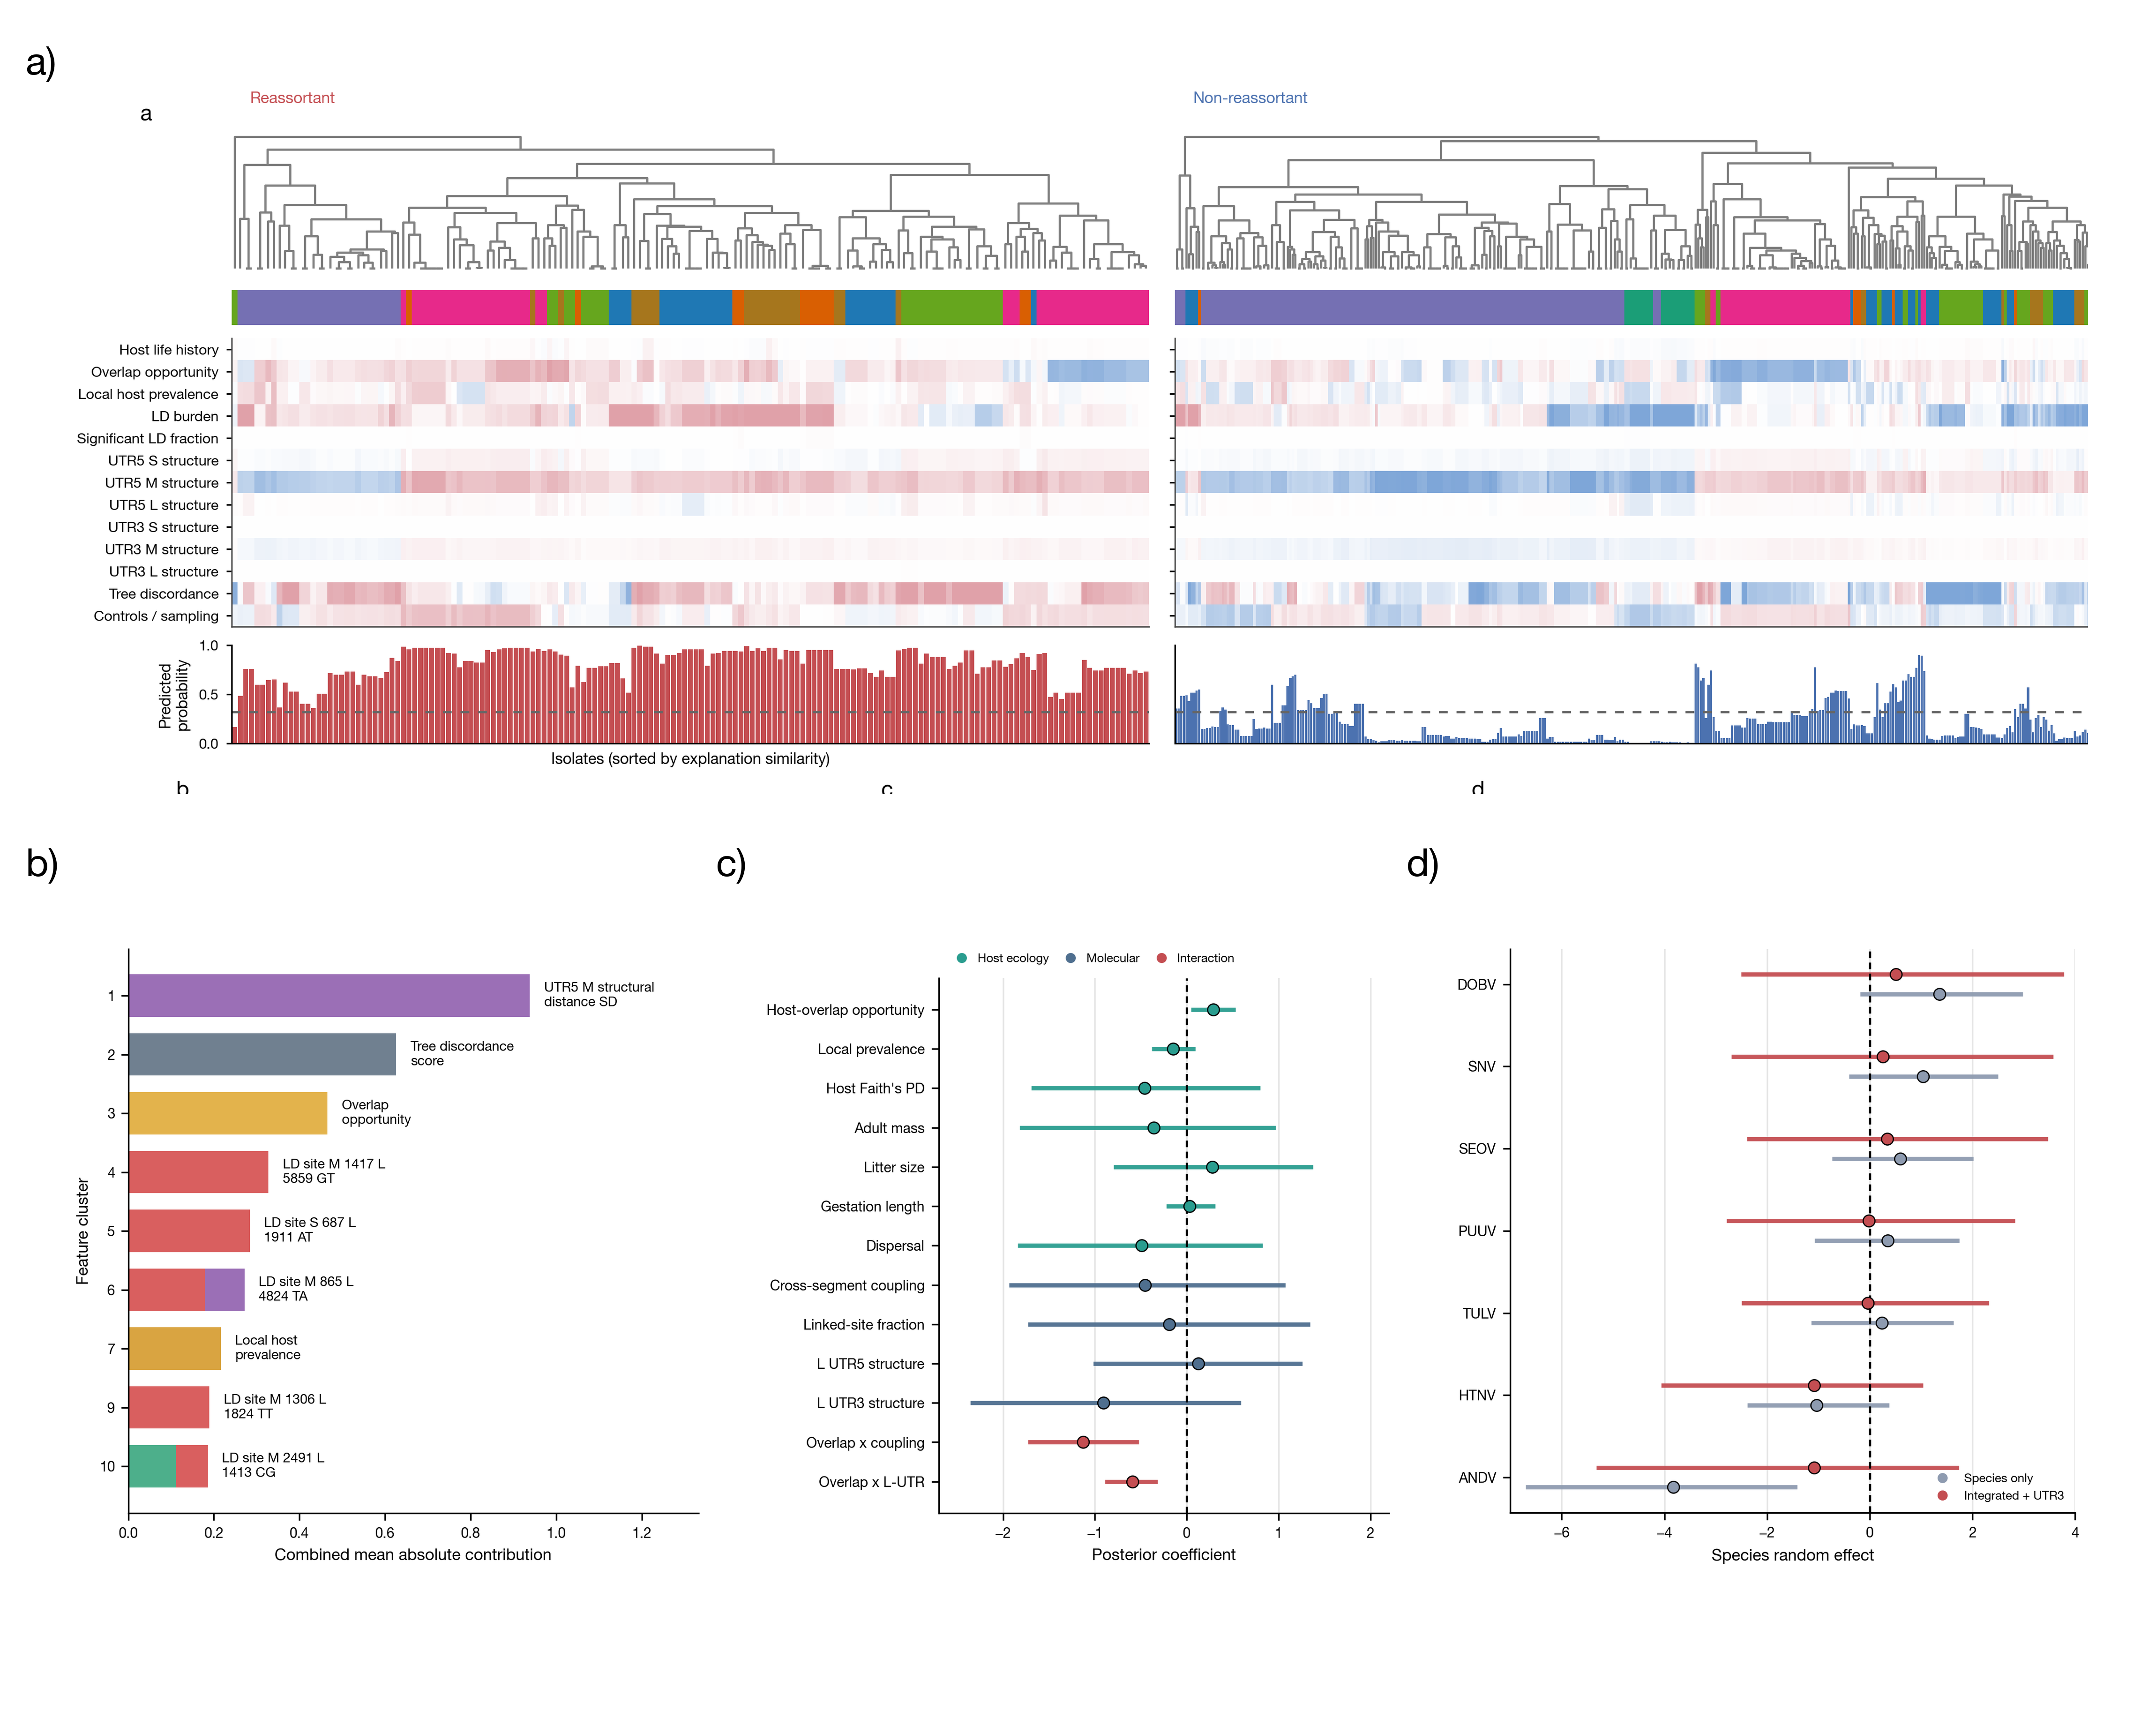

In [72]:
from IPython.display import Image as IPyImage, display

display(IPyImage(filename=str(OUT_PNG)))